# Customer Churn and Retention Analytics
Finding out why customers leave and predicting who is about to leave, so a business can spend its retention budget on the right people. For example, a Kenyan telecom, bank or subscription service that wants to keep customers from moving to a competitor.

In [2]:
import os, glob, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- settings ----------------
RANDOM_STATE = 42
TARGET = None              # None = find the column with "churn" in its name automatically
CV_MAX_ROWS = 60_000       # cross-validation uses at most this many rows, to keep it fast
OFFER_COST = 20.0          # assumed cost of one retention offer
VALUE_OF_SAVED_CUSTOMER = 300.0   # assumed value kept when a customer is retained
SAVE_RATE = 0.30           # assumed share of targeted churners the offer actually keeps
FIG_DIR = "reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

is_num = pd.api.types.is_numeric_dtype

In [3]:
files = sorted(glob.glob("data/*.csv"))
assert files, "No CSV found. Put the Kaggle file(s) in the data/ folder."
parts = [pd.read_csv(f) for f in files]
print("Loaded:", files)
df = pd.concat(parts, ignore_index=True) if len(parts) > 1 else parts[0]
print("Shape:", df.shape)
display(df.head())
df.info()

Loaded: ['data\\customer_churn_data.csv']
Shape: (5880, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,...,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes


<class 'pandas.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5880 non-null   str    
 1   gender            5880 non-null   str    
 2   SeniorCitizen     5880 non-null   int64  
 3   Partner           5880 non-null   str    
 4   Dependents        5880 non-null   str    
 5   tenure            5880 non-null   int64  
 6   PhoneService      5880 non-null   str    
 7   MultipleLines     5880 non-null   str    
 8   InternetService   5880 non-null   str    
 9   OnlineSecurity    5880 non-null   str    
 10  OnlineBackup      5880 non-null   str    
 11  DeviceProtection  5880 non-null   str    
 12  TechSupport       5880 non-null   str    
 13  StreamingTV       5880 non-null   str    
 14  StreamingMovies   5880 non-null   str    
 15  Contract          5880 non-null   str    
 16  PaperlessBilling  5880 non-null   str    
 17  Paymen

## 1. Cleaning the data
Finding the churn column, turning it into 0 and 1, fixing text columns that hold numbers, and removing ID columns and duplicate rows.

In [4]:
# find the column that says whether the customer left
if TARGET is None:
    cands = [c for c in df.columns if "churn" in c.lower()]
    assert cands, "Could not find a churn column. Set TARGET yourself in the settings cell."
    TARGET = cands[0]
print("Target column:", TARGET)

# tidy text columns: trim spaces, blank text -> missing, numbers stored as text -> real numbers
for c in df.columns:
    if c == TARGET or is_num(df[c]):
        continue
    s = df[c].astype("string").str.strip().replace("", pd.NA)
    as_num = pd.to_numeric(s, errors="coerce")
    df[c] = as_num if as_num.notna().sum() >= 0.9 * s.notna().sum() and s.notna().sum() > 0 else s.astype("object")
    if is_num(df[c]) and df[c].isna().sum() > 0:
        print(f"  '{c}': text numbers converted; {int(df[c].isna().sum())} blank -> missing")

# churn -> 1 (left) / 0 (stayed)
POSITIVE = {"yes", "y", "true", "1", "churn", "churned", "left", "exited", "attrited", "cancelled", "canceled"}
t = df[TARGET]
if is_num(t):
    df["_y"] = (t == t.max()).astype(float).where(t.notna())
else:
    df["_y"] = t.astype(str).str.strip().str.lower().isin(POSITIVE).astype(float).where(t.notna())
n0 = len(df)
df = df[df["_y"].notna()].copy()
df["_y"] = df["_y"].astype(int)
print(f"Rows with a missing churn answer dropped: {n0 - len(df)}")
df = df.drop(columns=[TARGET]).rename(columns={"_y": "churn"})

# drop ID columns (they identify a customer but say nothing about why they leave) and duplicates
id_cols = [c for c in df.columns if c != "churn" and (
    re.search(r"(^|[^a-z])id($|[^a-z])|customerid|custid", c.lower())
    or (df[c].nunique() == len(df) and not (is_num(df[c]) and df[c].dtype.kind == "f")))]
print("ID columns dropped:", id_cols)
df = df.drop(columns=id_cols)
print("Duplicate rows removed:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)

# text columns with too many different values cannot be used as categories
hc = [c for c in df.columns if not is_num(df[c]) and df[c].nunique() > 50]
print("Columns with too many different values dropped:", hc)
df = df.drop(columns=hc)

print("\nMissing values per column (%):")
miss = (df.isna().mean() * 100).round(2)
display(miss[miss > 0] if miss.any() else "no missing values")
print(f"\nFinal shape {df.shape} | churn rate = {df['churn'].mean():.2%}")

Target column: Churn
Rows with a missing churn answer dropped: 0
ID columns dropped: ['customerID']
Duplicate rows removed: 0
Columns with too many different values dropped: []

Missing values per column (%):


'no missing values'


Final shape (5880, 20) | churn rate = 49.29%


## 2. Exploring the data
### 2.1 How many customers leave?

3 numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
16 category columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


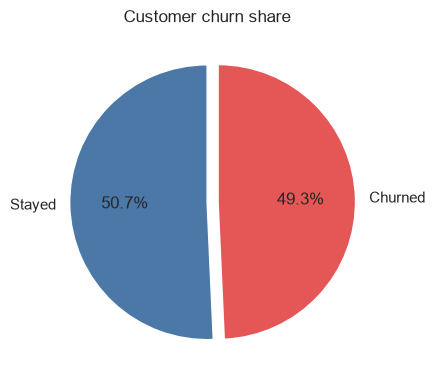

In [5]:
num_cols = [c for c in df.columns if c != "churn" and is_num(df[c]) and df[c].nunique() > 5]
cat_cols = [c for c in df.columns if c != "churn" and c not in num_cols]   # text + columns with few values
print(f"{len(num_cols)} numeric columns: {num_cols}")
print(f"{len(cat_cols)} category columns: {cat_cols}")

fig, ax = plt.subplots(figsize=(4.5, 4))
vc = df["churn"].value_counts().sort_index()
ax.pie(vc, labels=["Stayed", "Churned"], autopct="%1.1f%%", colors=["#4C78A8", "#E45756"],
       startangle=90, explode=(0, 0.08))
ax.set_title("Customer churn share")
savefig("01_churn_share")

### 2.2 Churn rate for each category
The red dashed line is the overall churn rate. A bar far above or below it would mean that group behaves differently.

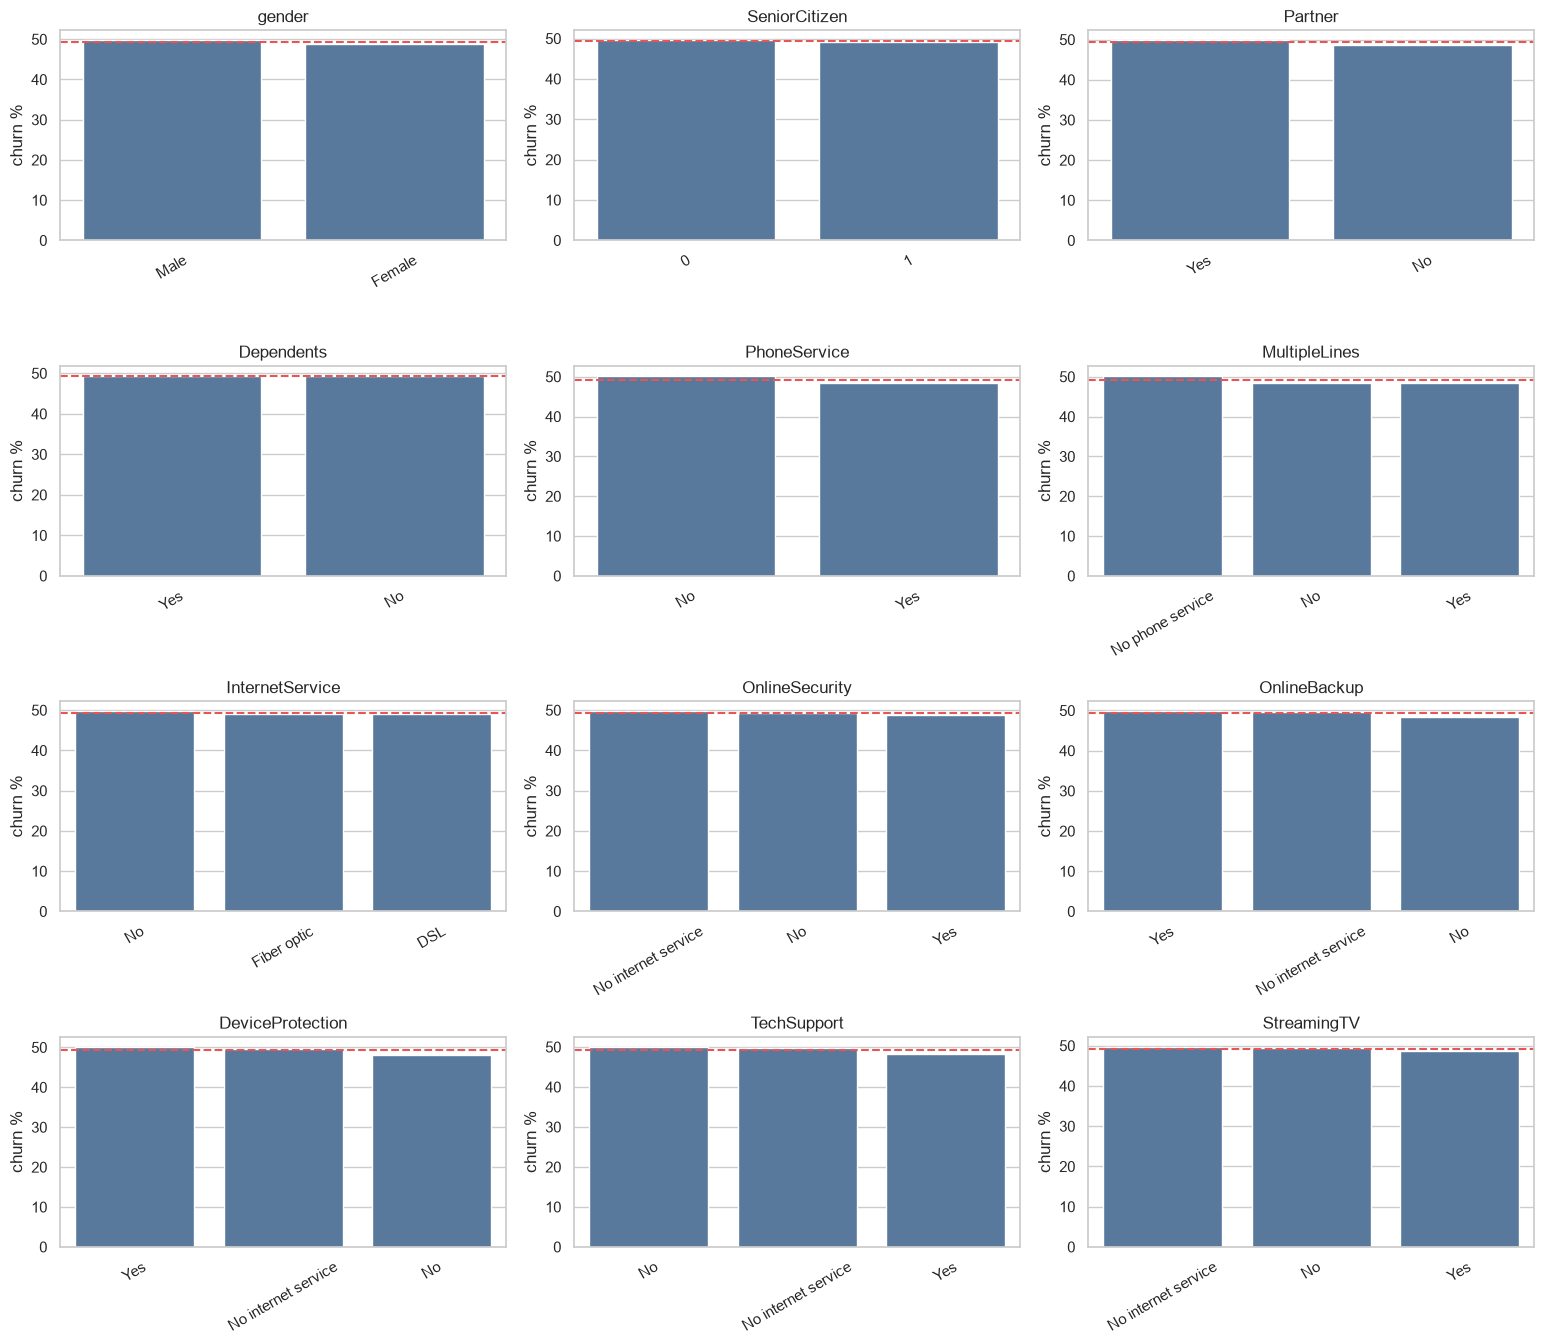

In [6]:
overall = df["churn"].mean()
plot_cats = cat_cols[:12]
ncol = 3
nrow = int(np.ceil(len(plot_cats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.4 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, plot_cats):
    r = df.groupby(c, dropna=False)["churn"].mean().sort_values(ascending=False).head(10) * 100
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4C78A8")
    ax.axhline(overall * 100, color="#E45756", ls="--")
    ax.set_title(c); ax.set_ylabel("churn %"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
for ax in axes[len(plot_cats):]:
    ax.axis("off")
savefig("02_churn_by_category")

### 2.3 Numbers: customers who left vs stayed

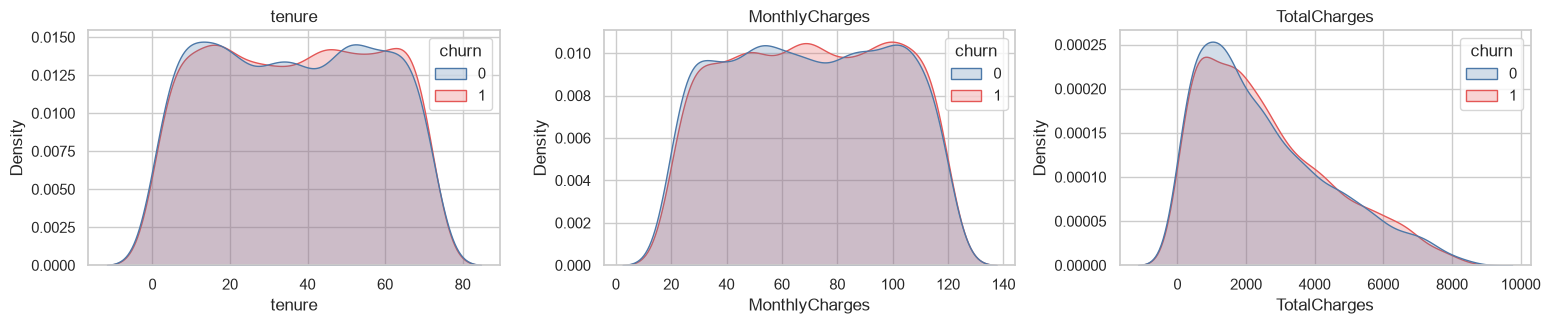

In [7]:
plot_nums = num_cols[:9]
ncol = 3
nrow = int(np.ceil(len(plot_nums) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.4 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, plot_nums):
    sns.kdeplot(data=df, x=c, hue="churn", common_norm=False, fill=True,
                palette={0: "#4C78A8", 1: "#E45756"}, ax=ax, warn_singular=False)
    ax.set_title(c)
for ax in axes[len(plot_nums):]:
    ax.axis("off")
savefig("03_numeric_by_churn")

## 3. Statistical analysis: which columns are linked to churn?
- **Category columns:** chi-square test, with **Cramér's V** as the strength (0 = no link, 1 = perfect link).
- **Number columns:** Mann-Whitney test, with the **rank-biserial correlation** as the strength (0 to 1).

A p-value below 0.05 means the link is unlikely to be chance. Look at the **strength** column too, because a link can be real but tiny.

,feature,type,strength,p_value,significant (p<0.05)
0,Contract,categorical,0.0234,0.2010,False
1,TotalCharges,numeric,0.0212,0.1586,False
2,MultipleLines,categorical,0.0180,0.3844,False
3,PhoneService,categorical,0.0177,0.1751,False
4,DeviceProtection,categorical,0.0176,0.4037,False
5,MonthlyCharges,numeric,0.0172,0.2540,False
6,TechSupport,categorical,0.0160,0.4699,False
7,OnlineBackup,categorical,0.0121,0.6497,False
8,StreamingMovies,categorical,0.0114,0.6835,False
9,PaymentMethod,categorical,0.0101,0.8953,False


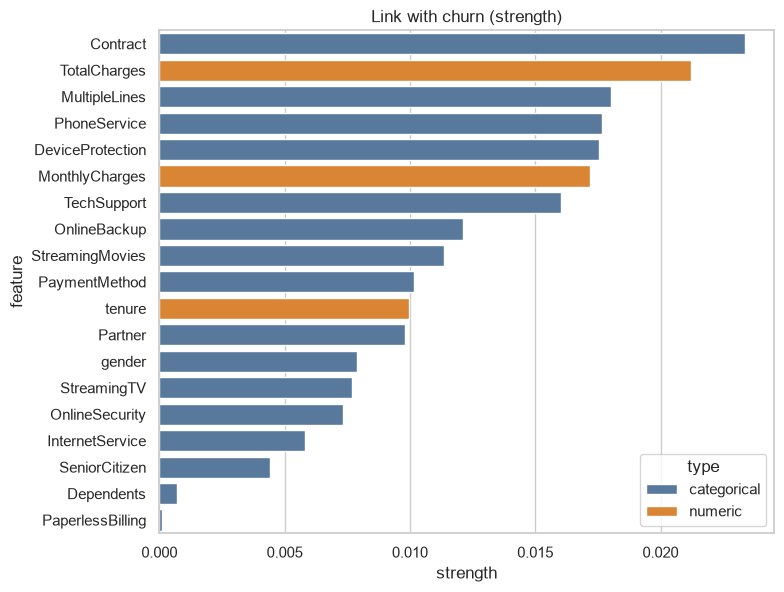

In [8]:
def assoc_cat(x, y):
    ct = pd.crosstab(x.fillna("missing").astype(str), y)
    if min(ct.shape) < 2:
        return np.nan, np.nan
    chi2, p = stats.chi2_contingency(ct)[:2]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), p

def assoc_num(x, y):
    m = x.notna()
    a, b = x[m & (y == 1)], x[m & (y == 0)]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return abs(2 * u / (len(a) * len(b)) - 1), p

rows = []
for c in cat_cols:
    s, p = assoc_cat(df[c], df["churn"]); rows.append((c, "categorical", s, p))
for c in num_cols:
    s, p = assoc_num(df[c], df["churn"]); rows.append((c, "numeric", s, p))

drivers = pd.DataFrame(rows, columns=["feature", "type", "strength", "p_value"])
drivers = drivers.sort_values("strength", ascending=False)
drivers["significant (p<0.05)"] = drivers["p_value"] < 0.05
display(drivers.round(4).reset_index(drop=True))
drivers.round(4).to_csv("reports/statistical_association.csv", index=False)

plt.figure(figsize=(8, max(3, 0.32 * len(drivers))))
sns.barplot(data=drivers, y="feature", x="strength", hue="type", dodge=False,
            palette={"categorical": "#4C78A8", "numeric": "#F58518"})
plt.title("Link with churn (strength)")
savefig("04_association_strength")

In [9]:
# Leakage check: a single column that predicts churn almost perfectly is suspicious,
# because it may be a result of the customer leaving rather than a cause.
suspects = []
for c in cat_cols + num_cols:
    x = df[c]
    if c in num_cols:
        enc = x
    else:
        key = x.fillna("missing").astype(str)
        enc = key.map(df.groupby(key)["churn"].mean())
    ok = enc.notna()
    auc = roc_auc_score(df.loc[ok, "churn"], enc[ok])
    if max(auc, 1 - auc) > 0.95:
        suspects.append((c, round(max(auc, 1 - auc), 3)))
print("Leakage check (one column with AUC above 0.95):", suspects if suspects else "none found")

Leakage check (one column with AUC above 0.95): none found


## 4. Creating new features
New columns built from existing ones, only when matching columns exist:
`tenure_bucket` (new vs loyal customers), `avg_charge_per_tenure` and `charge_gap` (spending compared with what the monthly charge implies), and `n_services` (how many services a customer has).

In [10]:
def find(*keys):
    for c in df.columns:
        if all(k in c.lower() for k in keys):
            return c

tenure = find("tenure")
monthly = find("monthly", "charge") or find("monthly") or find("charge")
total = find("total", "charge") or find("total", "spend") or find("total")
fe = df.copy()
created = []
if tenure and is_num(fe[tenure]):
    fe["tenure_bucket"] = pd.qcut(fe[tenure], q=5, duplicates="drop").astype(str)
    created.append("tenure_bucket")
    if total and is_num(fe[total]):
        fe["avg_charge_per_tenure"] = fe[total] / (fe[tenure] + 1)
        created.append("avg_charge_per_tenure")
        if monthly and is_num(fe[monthly]):
            fe["charge_gap"] = fe[total] - fe[monthly] * fe[tenure]
            created.append("charge_gap")

yes_no = [c for c in cat_cols if set(df[c].dropna().astype(str).str.lower().unique())
          <= {"yes", "no", "no internet service", "no phone service"}]
if len(yes_no) >= 2:
    fe["n_services"] = sum((df[c].astype(str).str.lower() == "yes").astype(int) for c in yes_no)
    created.append("n_services")

print("tenure:", tenure, "| monthly:", monthly, "| total:", total, "| yes/no columns:", len(yes_no))
print("New features:", created if created else "none")
if "tenure_bucket" in created:
    display(fe.groupby("tenure_bucket")["churn"].agg(["mean", "size"]).round(3))

tenure: tenure | monthly: MonthlyCharges | total: TotalCharges | yes/no columns: 11
New features: ['tenure_bucket', 'avg_charge_per_tenure', 'charge_gap', 'n_services']


,mean,size
tenure_bucket,,
"(0.999, 15.0]",0.480,1250
"(15.0, 29.0]",0.502,1124
"(29.0, 44.0]",0.495,1176
"(44.0, 58.0]",0.489,1168
"(58.0, 72.0]",0.500,1162


## 5. Building the models
We hold out 20% of customers as a final test. All preparation (filling gaps, scaling numbers, turning categories into 0/1 columns) sits **inside a Pipeline**, so it is learned from the training part only. Then we compare three models with 5-fold cross-validation: the training data is cut into 5 parts, and each part takes a turn as the mini test.

In [11]:
X = fe.drop(columns="churn")
y = fe["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_f = [c for c in X.columns if is_num(X[c])]
cat_f = [c for c in X.columns if c not in num_f]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=0.01)
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_f),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), cat_f)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06, class_weight="balanced",
                                                        random_state=RANDOM_STATE),
}
pipes = {n: Pipeline([("prep", prep), ("model", m)]) for n, m in models.items()}
print(f"train={len(X_train):,} test={len(X_test):,} | numeric={len(num_f)} category={len(cat_f)} "
      f"| churn rate in train={y_train.mean():.2%}")

cv_idx = X_train.sample(CV_MAX_ROWS, random_state=RANDOM_STATE).index if len(X_train) > CV_MAX_ROWS else X_train.index
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for n, p in pipes.items():
    r = cross_validate(p, X_train.loc[cv_idx], y_train.loc[cv_idx], cv=cv,
                       scoring=["roc_auc", "f1", "precision", "recall"], n_jobs=1)
    cv_rows[n] = {k: f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}"
                  for k in ["roc_auc", "f1", "precision", "recall"]}
cv_table = pd.DataFrame(cv_rows).T
cv_table.columns = ["ROC-AUC", "F1", "Precision", "Recall"]
print("5-fold cross-validation on the training data (average ± spread):")
display(cv_table)

train=4,704 test=1,176 | numeric=7 category=16 | churn rate in train=49.28%
5-fold cross-validation on the training data (average ± spread):


,ROC-AUC,F1,Precision,Recall
Logistic Regression,0.479 ± 0.004,0.490 ± 0.013,0.480 ± 0.014,0.500 ± 0.018
Random Forest,0.495 ± 0.014,0.479 ± 0.014,0.485 ± 0.014,0.473 ± 0.016
Gradient Boosting,0.505 ± 0.009,0.494 ± 0.007,0.492 ± 0.013,0.497 ± 0.011


## 6. Testing the models on customers they have never seen
**Precision:** of the customers we flag as likely to leave, how many really would. **Recall:** of all customers who really leave, how many we catch. **ROC-AUC:** how well the model ranks leavers above stayers (0.5 = a coin flip, 1.0 = perfect).

,Precision,Recall,F1,ROC-AUC,PR-AUC
Gradient Boosting,0.4770,0.4828,0.4799,0.4877,0.4813
Random Forest,0.4933,0.5052,0.4991,0.4850,0.5028
Logistic Regression,0.4726,0.4759,0.4742,0.4735,0.4786


Best model (test ROC-AUC): Gradient Boosting


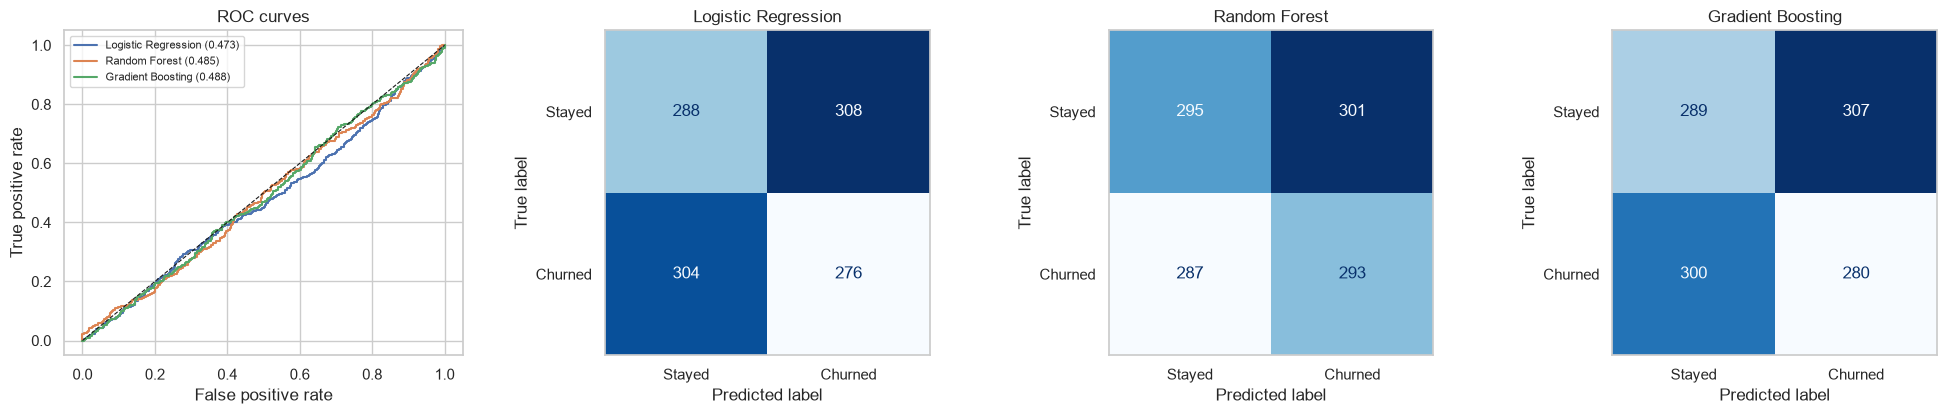

In [12]:
test_proba = {}
for n, p in pipes.items():
    p.fit(X_train, y_train)
    test_proba[n] = p.predict_proba(X_test)[:, 1]

def evaluate(proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "PR-AUC": average_precision_score(y_test, proba)}

results = pd.DataFrame({n: evaluate(p) for n, p in test_proba.items()}).T.sort_values("ROC-AUC", ascending=False)
display(results.round(4))
results.round(4).to_csv("reports/model_comparison_test.csv")
best = results.index[0]
print("Best model (test ROC-AUC):", best)

fig, ax = plt.subplots(1, 1 + len(pipes), figsize=(5 * (1 + len(pipes)), 4.3))
for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].legend(fontsize=8); ax[0].set_title("ROC curves"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
for a, (n, p) in zip(ax[1:], test_proba.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= 0.5).astype(int)), display_labels=["Stayed", "Churned"]).plot(
        ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(n); a.grid(False)
savefig("05_model_evaluation")

### Reality check: is there any signal at all?
A model is only useful if it beats a coin flip. This cell checks that, and the verdict feeds into the final findings.

In [13]:
best_auc = results.loc[best, "ROC-AUC"]
strongest = drivers["strength"].max()
n_sig = int(drivers["significant (p<0.05)"].sum())
print(f"Best test ROC-AUC: {best_auc:.3f}   (a pure coin flip scores 0.500)")
print(f"Strongest link between any column and churn: {strongest:.3f}   (0 = none, 1 = perfect)")
print(f"Columns significantly linked to churn: {n_sig} of {len(drivers)}")

has_signal = (best_auc >= 0.60) or (n_sig >= 3)
if has_signal:
    print("\nVERDICT: the data carries a usable signal about who is likely to churn.")
else:
    print("\nVERDICT: the data carries almost no signal. The models are no better than a coin flip,")
    print("so churn in this file is not explained by any of its columns.")

Best test ROC-AUC: 0.488   (a pure coin flip scores 0.500)
Strongest link between any column and churn: 0.023   (0 = none, 1 = perfect)
Columns significantly linked to churn: 0 of 19

VERDICT: the data carries almost no signal. The models are no better than a coin flip,
so churn in this file is not explained by any of its columns.


## 7. What drives churn?
Two views on the best model. **Permutation importance:** shuffle one column and see how much the model gets worse (a bigger drop means the model relies on that column more). **Logistic regression coefficients:** which way each value pushes the churn risk. If the verdict above says there is no signal, treat these charts as noise.

,drop in ROC-AUC
PaymentMethod,0.0113
MonthlyCharges,0.0097
TotalCharges,0.0071
gender,0.0052
PaperlessBilling,0.0048
Contract,0.0047
charge_gap,0.0031
OnlineBackup,0.0030
MultipleLines,0.0028
DeviceProtection,0.0012


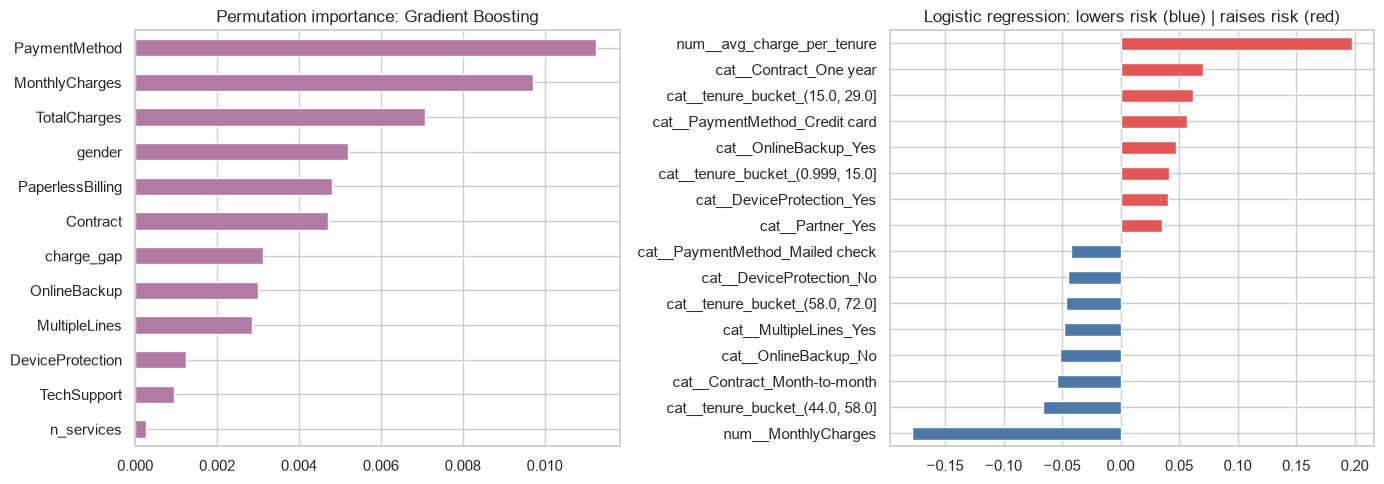

In [14]:
best_pipe = pipes[best]
samp = X_test.sample(min(len(X_test), 6000), random_state=RANDOM_STATE)
pi = permutation_importance(best_pipe, samp, y_test.loc[samp.index], scoring="roc_auc",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(imp.head(10).round(4).to_frame("drop in ROC-AUC"))

lr = pipes["Logistic Regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
top_coef = pd.concat([coef.head(8), coef.tail(8)])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.head(12).sort_values().plot.barh(ax=ax[0], color="#B279A2")
ax[0].set_title(f"Permutation importance: {best}")
top_coef.plot.barh(ax=ax[1], color=["#4C78A8" if v < 0 else "#E45756" for v in top_coef])
ax[1].set_title("Logistic regression: lowers risk (blue) | raises risk (red)")
savefig("06_churn_drivers")

## 8. Retention strategy
### 8.1 Which groups churn the most?

In [15]:
top_feats = [f for f in imp.index if f in fe.columns][:6]
seg_rows = []
for c in top_feats:
    if is_num(fe[c]) and fe[c].nunique() > 8:
        g = fe.groupby(pd.qcut(fe[c], 4, duplicates="drop").astype(str))["churn"].agg(["mean", "size"])
    else:
        g = fe.groupby(fe[c].astype(str))["churn"].agg(["mean", "size"])
    g = g[g["size"] >= max(30, 0.01 * len(fe))].sort_values("mean", ascending=False)
    for level, r in g.head(2).iterrows():
        seg_rows.append({"feature": c, "segment": level, "customers": int(r["size"]),
                         "churn_rate": r["mean"], "vs_overall": r["mean"] / overall})
segments = pd.DataFrame(seg_rows).sort_values("churn_rate", ascending=False)
display(segments.round(3))
segments.round(3).to_csv("reports/high_risk_segments.csv", index=False)

,feature,segment,customers,churn_rate,vs_overall
10,Contract,One year,1954,0.505,1.024
4,TotalCharges,"(2136.445, 3767.665]",1470,0.501,1.017
5,TotalCharges,"(3767.665, 8589.6]",1470,0.501,1.016
2,MonthlyCharges,"(95.458, 119.99]",1470,0.500,1.014
0,PaymentMethod,Credit card,1503,0.499,1.012
11,Contract,Two year,1906,0.497,1.009
6,gender,Male,2950,0.497,1.008
1,PaymentMethod,Electronic check,1488,0.495,1.004
3,MonthlyCharges,"(45.718, 70.155]",1470,0.495,1.003
8,PaperlessBilling,Yes,2890,0.493,1.000


### 8.2 Risk scores and lift
We rank the test customers from highest to lowest predicted churn risk and cut them into 10 equal groups (decile 1 = riskiest). **Lift** = the churn rate in that group divided by the overall churn rate. A good model has a lift well above 1 in decile 1; a lift near 1 everywhere means the model cannot tell customers apart.### 8.2 Risk scores and lift
We rank the test customers from highest to lowest predicted churn risk and cut them into 10 equal groups (decile 1 = riskiest). **Lift** = the churn rate in that group divided by the overall churn rate. A good model has a lift well above 1 in decile 1; a lift near 1 everywhere means the model cannot tell customers apart.

In [16]:
score = pd.DataFrame({"p": test_proba[best], "y": y_test.values})
score["decile"] = pd.qcut(score["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = score.groupby("decile").agg(customers=("y", "size"), churners=("y", "sum"), churn_rate=("y", "mean"))
lift["lift"] = lift["churn_rate"] / score["y"].mean()
lift["cum_capture_%"] = lift["churners"].cumsum() / lift["churners"].sum() * 100
display(lift.round(3))
lift.round(3).to_csv("reports/lift_table.csv")

risk_tier = pd.cut(score["p"], [0, 0.4, 0.7, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
display(score.groupby(risk_tier).agg(customers=("y", "size"), actual_churn_rate=("y", "mean")).round(3))

,customers,churners,churn_rate,lift,cum_capture_%
decile,,,,,
1,118,55,0.466,0.945,9.483
2,118,58,0.492,0.997,19.483
3,117,54,0.462,0.936,28.793
4,118,65,0.551,1.117,40.000
5,117,48,0.410,0.832,48.276
6,118,63,0.534,1.083,59.138
7,117,64,0.547,1.109,70.172
8,118,57,0.483,0.979,80.000
9,117,50,0.427,0.866,88.621


,customers,actual_churn_rate
p,,
Low,279,0.487
Medium,797,0.501
High,100,0.450


### 8.3 Campaign simulation: whom should we target?
Assumptions (set in the settings cell): each retention offer costs `OFFER_COST`. If the customer would have left, the offer keeps them with probability `SAVE_RATE`, and we keep `VALUE_OF_SAVED_CUSTOMER`. We contact customers from riskiest to safest and look at where the total benefit is highest.

Best campaign: target the riskiest 100% of customers (1,176 of 1,176) -> expected net benefit 28,680
(targeting everyone: 28,680; targeting nobody: 0)


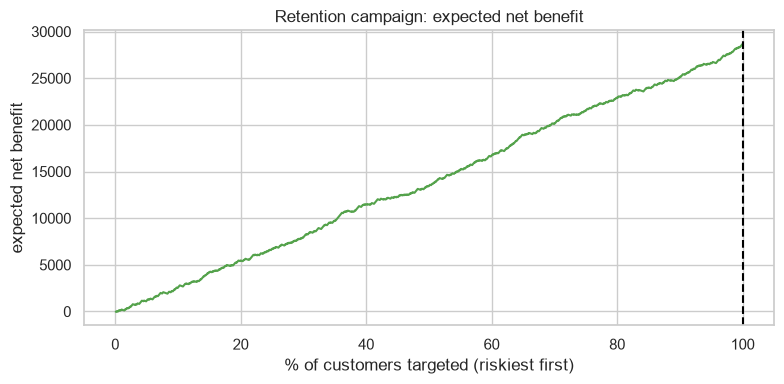

In [17]:
order = score.sort_values("p", ascending=False).reset_index(drop=True)
k = np.arange(1, len(order) + 1)
tp_cum = order["y"].cumsum().values
net = tp_cum * SAVE_RATE * VALUE_OF_SAVED_CUSTOMER - k * OFFER_COST
best_k = int(net.argmax()) + 1
print(f"Best campaign: target the riskiest {best_k / len(order):.0%} of customers ({best_k:,} of {len(order):,}) "
      f"-> expected net benefit {net.max():,.0f}")
print(f"(targeting everyone: {net[-1]:,.0f}; targeting nobody: 0)")

plt.figure(figsize=(8, 4))
plt.plot(k / len(order) * 100, net, color="#54A24B")
plt.axvline(best_k / len(order) * 100, color="black", ls="--")
plt.xlabel("% of customers targeted (riskiest first)")
plt.ylabel("expected net benefit")
plt.title("Retention campaign: expected net benefit")
savefig("07_campaign_simulation")

## 9. Dashboard and key findings

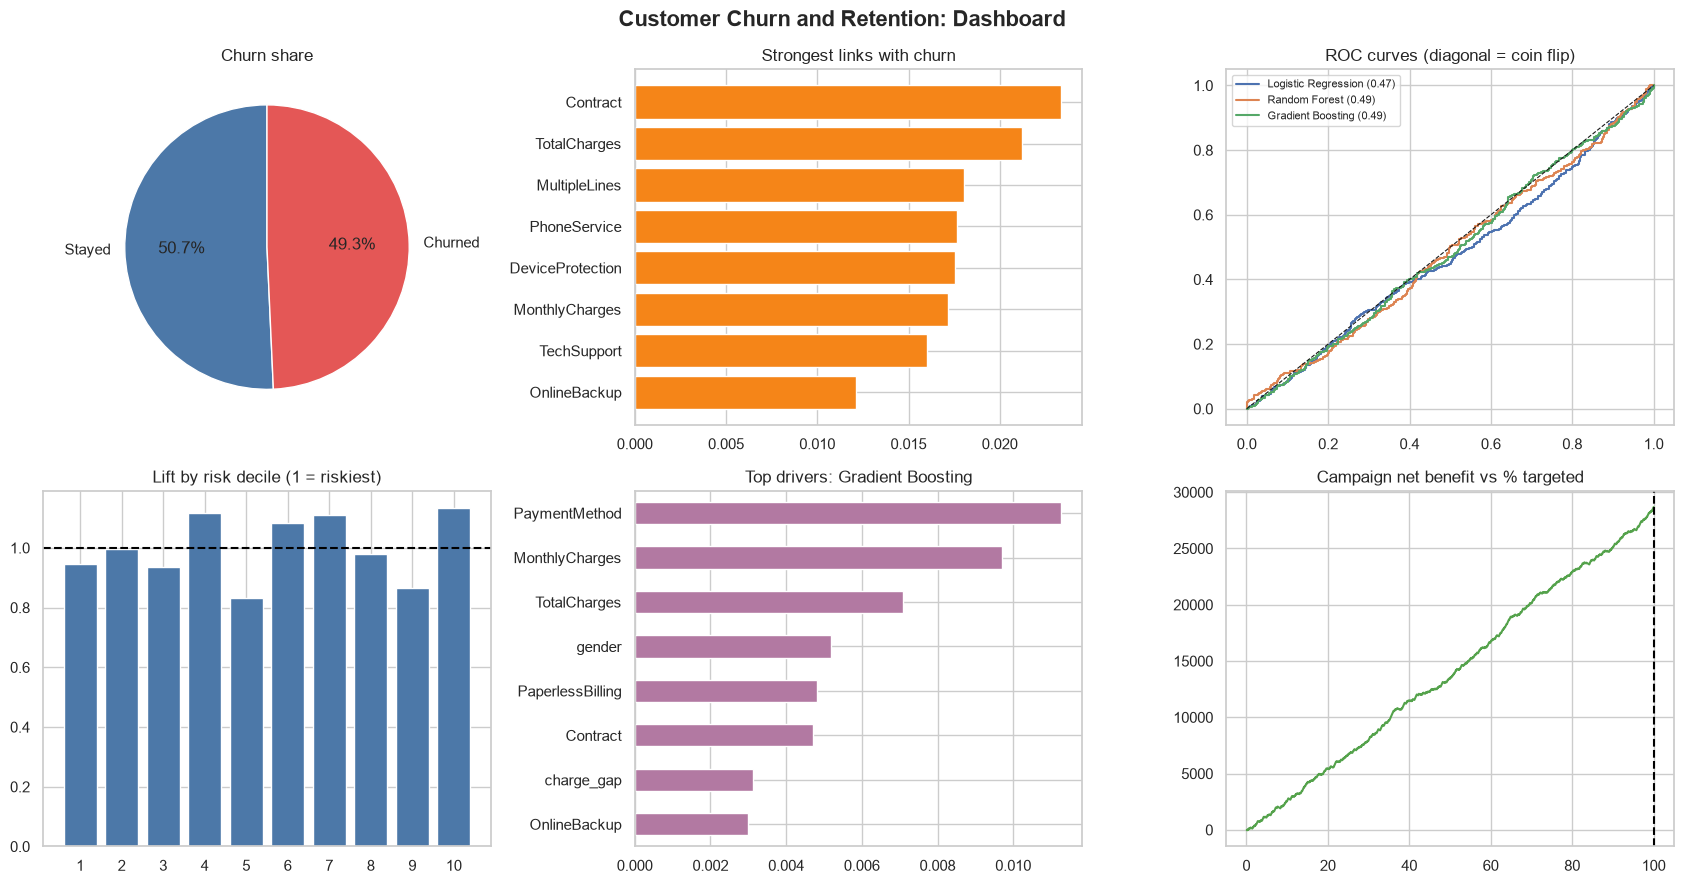

In [18]:
fig = plt.figure(figsize=(17, 9))
grid = fig.add_gridspec(2, 3)

ax = fig.add_subplot(grid[0, 0])
ax.pie(vc, labels=["Stayed", "Churned"], autopct="%1.1f%%", colors=["#4C78A8", "#E45756"], startangle=90)
ax.set_title("Churn share")

ax = fig.add_subplot(grid[0, 1])
d = drivers.head(8).iloc[::-1]
ax.barh(d["feature"], d["strength"], color="#F58518")
ax.set_title("Strongest links with churn")

ax = fig.add_subplot(grid[0, 2])
for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, p):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.legend(fontsize=8); ax.set_title("ROC curves (diagonal = coin flip)")

ax = fig.add_subplot(grid[1, 0])
ax.bar(lift.index.astype(str), lift["lift"], color="#4C78A8")
ax.axhline(1, color="black", ls="--")
ax.set_title("Lift by risk decile (1 = riskiest)")

ax = fig.add_subplot(grid[1, 1])
imp.head(8).sort_values().plot.barh(ax=ax, color="#B279A2")
ax.set_title(f"Top drivers: {best}")

ax = fig.add_subplot(grid[1, 2])
ax.plot(k / len(order) * 100, net, color="#54A24B")
ax.axvline(best_k / len(order) * 100, color="black", ls="--")
ax.set_title("Campaign net benefit vs % targeted")

fig.suptitle("Customer Churn and Retention: Dashboard", fontsize=16, fontweight="bold")
savefig("00_dashboard")

In [19]:
top1 = lift.iloc[0]
verdict = ("The data carries a usable signal about who churns."
           if has_signal else
           "The data carries almost no signal: the models are no better than a coin flip, so these results should not be used to target customers.")

print(f"""
KEY FINDINGS
0. {verdict}
1. Overall churn rate: {overall:.1%} ({int(df['churn'].sum()):,} of {len(df):,} customers).
2. Best model: {best}, ROC-AUC {results.loc[best, 'ROC-AUC']:.3f}, recall {results.loc[best, 'Recall']:.1%}, precision {results.loc[best, 'Precision']:.1%} (threshold 0.5).
3. Columns significantly linked to churn: {n_sig} of {len(drivers)}; strongest link {strongest:.3f} (0 = none, 1 = perfect).
4. Riskiest decile churns at {top1['churn_rate']:.1%}, which is {top1['lift']:.1f}x the average; the top 30% of customers contain {lift['cum_capture_%'].iloc[2]:.0f}% of churners.
5. Campaign simulation: best is to target the riskiest {best_k / len(order):.0%}, net benefit {net.max():,.0f} (targeting everyone: {net[-1]:,.0f}).
""")


KEY FINDINGS
0. The data carries almost no signal: the models are no better than a coin flip, so these results should not be used to target customers.
1. Overall churn rate: 49.3% (2,898 of 5,880 customers).
2. Best model: Gradient Boosting, ROC-AUC 0.488, recall 48.3%, precision 47.7% (threshold 0.5).
3. Columns significantly linked to churn: 0 of 19; strongest link 0.023 (0 = none, 1 = perfect).
4. Riskiest decile churns at 46.6%, which is 0.9x the average; the top 30% of customers contain 29% of churners.
5. Campaign simulation: best is to target the riskiest 100%, net benefit 28,680 (targeting everyone: 28,680).



## Conclusions and recommendations
1. **Check for signal before building a strategy.** In this dataset, churn is not linked to any column: no feature is statistically significant, the best model scores a ROC-AUC of about 0.49 (a coin flip is 0.50), and the lift is about 1 in every risk group. The models cannot tell who will leave.
2. **Do not use these scores to target customers.** A model with no lift adds nothing. With a churn rate near 50%, an offer to everyone pays for itself under our assumptions, but that is because so many customers leave, not because the model helps.
3. **Look at the data itself.** A churn rate near 50%, evenly spread categories and no link between tenure, contract type or charges and churn are unusual for real telecom data. This suggests the file may be simulated or the churn labels may not be linked to these customer records.
4. **Collect better data.** Real churn work needs behaviour that changes before someone leaves: usage trends, complaints, support calls, late payments and recent price changes.
5. **Test with a control group.** Whatever the data, hold out a random group of high-risk customers from any campaign, to measure the real effect of the offer.

**Limitations.** Links are not proof of cause. The campaign economics are assumptions. The data is not Kenyan data, and it appears to be simulated. If the data changes, re-run the notebook and rewrite these conclusions from the new findings.